# 07 — Linear & Quadratic Discriminant Analysis

## Loan Default Risk Classification (Binary Task)


## 1. Imports and Configuration


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Preprocessing Setup


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Binary target
y = (df['Loan_Default'] == 'Yes').astype(int)

# Exclude leakage
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

# Preprocessor: Note that continuous standardized features are essential for LDA/QDA
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')


## 3. Fitting LDA and QDA on Loan Default


In [3]:
# Transform datasets
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

# 1. Fit Linear Discriminant Analysis
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_trans, y_train)
y_pred_lda = lda.predict(X_test_trans)
y_prob_lda = lda.predict_proba(X_test_trans)[:, 1]

# 2. Fit Quadratic Discriminant Analysis with reg_param shrinkage
# Note: plain QDA without reg_param triggers collinearity warnings with one-hot dummies
qda_reg = QuadraticDiscriminantAnalysis(reg_param=0.3)
qda_reg.fit(X_train_trans, y_train)
y_pred_qda = qda_reg.predict(X_test_trans)
y_prob_qda = qda_reg.predict_proba(X_test_trans)[:, 1]

# Also benchmark Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr.fit(X_train_trans, y_train)
y_prob_lr = lr.predict_proba(X_test_trans)[:, 1]

# Compile Comparative Table
df_discrim_comp = pd.DataFrame([
    {
        'Model': 'Linear Discriminant Analysis (LDA)',
        'Accuracy': accuracy_score(y_test, y_pred_lda),
        'Precision': precision_score(y_test, y_pred_lda),
        'Recall': recall_score(y_test, y_pred_lda),
        'F1_Score': f1_score(y_test, y_pred_lda),
        'ROC_AUC': roc_auc_score(y_test, y_prob_lda)
    },
    {
        'Model': 'Regularized QDA (reg_param=0.3)',
        'Accuracy': accuracy_score(y_test, y_pred_qda),
        'Precision': precision_score(y_test, y_pred_qda),
        'Recall': recall_score(y_test, y_pred_qda),
        'F1_Score': f1_score(y_test, y_pred_qda),
        'ROC_AUC': roc_auc_score(y_test, y_prob_qda)
    },
    {
        'Model': 'Logistic Regression Baseline',
        'Accuracy': accuracy_score(y_test, lr.predict(X_test_trans)),
        'Precision': precision_score(y_test, lr.predict(X_test_trans)),
        'Recall': recall_score(y_test, lr.predict(X_test_trans)),
        'F1_Score': f1_score(y_test, lr.predict(X_test_trans)),
        'ROC_AUC': roc_auc_score(y_test, y_prob_lr)
    }
])

df_discrim_comp.to_csv('../../outputs/tables/discriminant_analysis_comparison.csv', index=False)
print('=== LDA vs. QDA vs. Logistic Regression ===')
display(df_discrim_comp)

=== LDA vs. QDA vs. Logistic Regression ===


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Linear Discriminant Analysis (LDA),0.8630,0.724265,0.497475,0.589820,0.886874
1,Regularized QDA (reg_param=0.3),0.8335,0.588235,0.530303,0.557769,0.845648
2,Logistic Regression Baseline,0.8650,0.720280,0.520202,0.604106,0.890460


## 4. LDA Projection onto Canonical Discriminant Axes for Risk_Category


In [4]:
# Extract numeric features and multiclass target
y_risk = df['Risk_Category']
X_num = df[numeric_cols].fillna(df[numeric_cols].median())

# Fit multiclass LDA for projection
lda_proj = LinearDiscriminantAnalysis(n_components=2)
X_lda_2d = lda_proj.fit_transform(X_num, y_risk)

explained_variance_ratio = lda_proj.explained_variance_ratio_

print('=== Canonical Discriminant Analysis Projection ===')
print(f'Number of Discriminant Axes: {len(explained_variance_ratio)}')
print(f'LD1 Explained Variance Ratio: {explained_variance_ratio[0]*100:.2f}%')
print(f'LD2 Explained Variance Ratio: {explained_variance_ratio[1]*100:.2f}%')

=== Canonical Discriminant Analysis Projection ===
Number of Discriminant Axes: 2
LD1 Explained Variance Ratio: 98.59%
LD2 Explained Variance Ratio: 1.41%


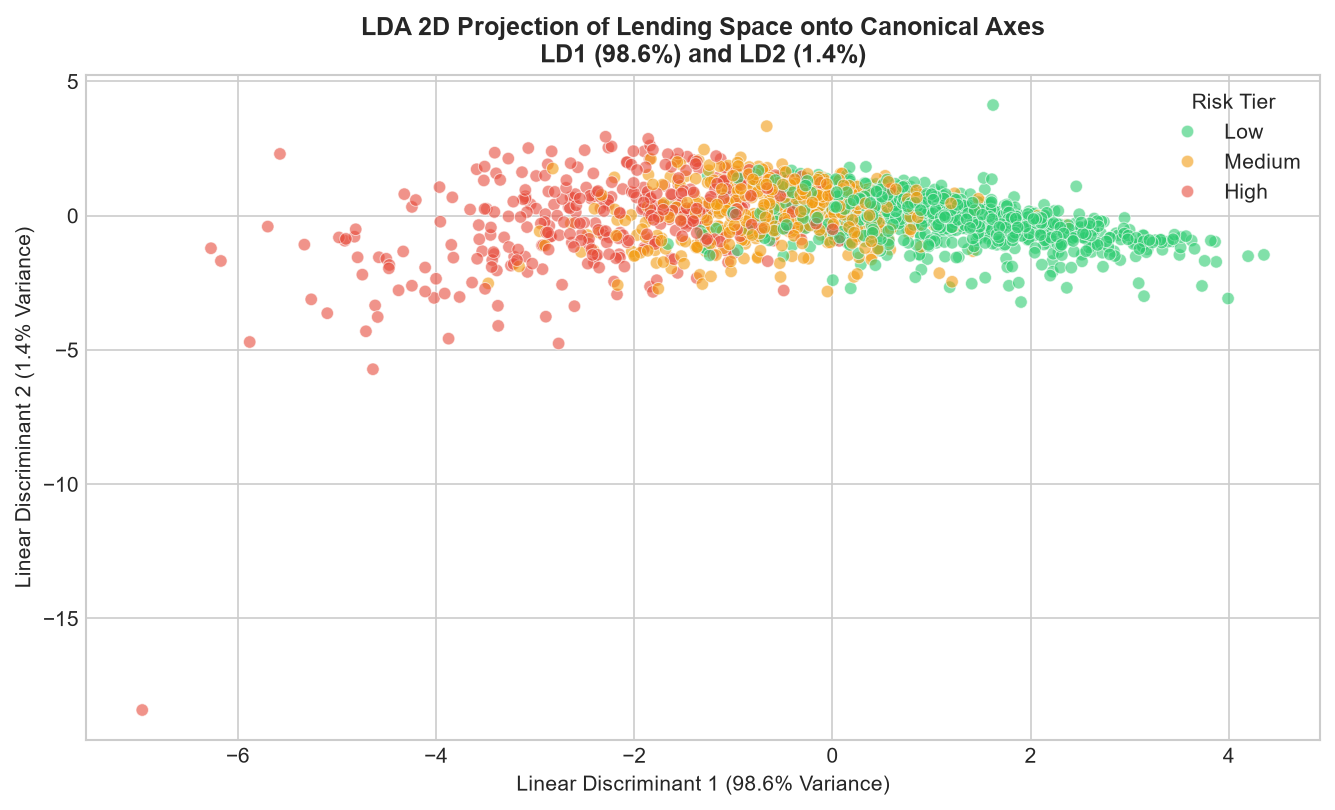

In [5]:
# Visualise LD1 vs LD2 Projection
df_proj = pd.DataFrame(X_lda_2d, columns=['LD1', 'LD2'])
df_proj['Risk_Category'] = y_risk

fig, ax = plt.subplots(figsize=(9, 5.5))
palette = {'Low': '#2ecc71', 'Medium': '#f39c12', 'High': '#e74c3c'}

sns.scatterplot(
    data=df_proj.sample(2000, random_state=RANDOM_STATE),
    x='LD1', y='LD2', hue='Risk_Category', palette=palette, alpha=0.6, ax=ax
)

ax.set_title(f'LDA 2D Projection of Lending Space onto Canonical Axes\nLD1 ({explained_variance_ratio[0]*100:.1f}%) and LD2 ({explained_variance_ratio[1]*100:.1f}%)', weight='bold')
ax.set_xlabel(f'Linear Discriminant 1 ({explained_variance_ratio[0]*100:.1f}% Variance)')
ax.set_ylabel(f'Linear Discriminant 2 ({explained_variance_ratio[1]*100:.1f}% Variance)')
ax.legend(title='Risk Tier')

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_lda_projection.png', dpi=150)
plt.show()

## 5. Covariance Matrix Comparison & Prior Shift Mechanics


In [6]:
# Compare covariance determinants for numeric features
cov_non_def = X_num[y == 0].cov()
cov_def = X_num[y == 1].cov()

# Compare log-determinants (measure of generalized dispersion volume)
_, logdet_non_def = np.linalg.slogdet(cov_non_def)
_, logdet_def = np.linalg.slogdet(cov_def)

# Compare standard deviations of key features
std_comp = pd.DataFrame({
    'Feature': ['Credit_Score', 'Debt_to_Income', 'Credit_Utilization_Pct', 'Late_Payments_2Y'],
    'Non_Defaulter_Std': [X_num.loc[y==0, col].std() for col in ['Credit_Score', 'Debt_to_Income', 'Credit_Utilization_Pct', 'Late_Payments_2Y']],
    'Defaulter_Std': [X_num.loc[y==1, col].std() for col in ['Credit_Score', 'Debt_to_Income', 'Credit_Utilization_Pct', 'Late_Payments_2Y']]
})

print('=== Class-Specific Covariance & Dispersion ===')
print(f'Log-Determinant (Non-Defaulters): {logdet_non_def:.2f}')
print(f'Log-Determinant (Defaulters):     {logdet_def:.2f}')
display(std_comp)


=== Class-Specific Covariance & Dispersion ===
Log-Determinant (Non-Defaulters): 123.20
Log-Determinant (Defaulters):     125.61


,Feature,Non_Defaulter_Std,Defaulter_Std
0,Credit_Score,62.134496,59.752910
1,Debt_to_Income,0.175164,0.302899
2,Credit_Utilization_Pct,17.425929,17.269004
3,Late_Payments_2Y,0.558113,1.011810


### Prior Shift Mechanics


In [7]:
# Prior Shift Demonstration
prior_default = 0.20
prior_non_default = 0.80
prior_shift = np.log(prior_default / prior_non_default)

print('=== Prior Shift Calculation ===')
print(f'P(Default)     = {prior_default:.2f}')
print(f'P(Non-Default) = {prior_non_default:.2f}')
print(f'Prior Log-Ratio Shift ln(pi_1 / pi_0): {prior_shift:.4f}')

=== Prior Shift Calculation ===
P(Default)     = 0.20
P(Non-Default) = 0.80
Prior Log-Ratio Shift ln(pi_1 / pi_0): -1.3863
